In [1]:
import sys
sys.path.insert(0, "..")          # taake src/data.py import ho sake

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_data, split_data, model_features, TARGET

df = load_data()
print(df.shape)
df.head()

(30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [2]:
print(df.isna().sum().sum(), "missing values")
print(df.dtypes.value_counts())

rate = df[TARGET].mean()
print(f"Default rate: {rate:.4f}  ({df[TARGET].sum()} of {len(df)})")

0 missing values
int64    24
Name: count, dtype: int64
Default rate: 0.2212  (6636 of 30000)


In [3]:
for col in ["EDUCATION", "MARRIAGE", "PAY_0"]:
    print(col)
    print(df[col].value_counts().sort_index(), "\n")

EDUCATION
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64 

MARRIAGE
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64 

PAY_0
PAY_0
-2     2759
-1     5686
 0    14737
 1     3688
 2     2667
 3      322
 4       76
 5       26
 6       11
 7        9
 8       19
Name: count, dtype: int64 



In [4]:
X_train, X_test, y_train, y_test = split_data(df)
print(len(X_train), len(X_test))
print(f"train default rate: {y_train.mean():.4f} | test default rate: {y_test.mean():.4f}")

24000 6000
train default rate: 0.2212 | test default rate: 0.2212


In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix

dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pred = dummy.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print("Recall (defaulters pakde):", recall_score(y_test, pred))
print(confusion_matrix(y_test, pred))

Accuracy: 0.7788
Recall (defaulters pakde): 0.0
[[4673    0]
 [1327    0]]


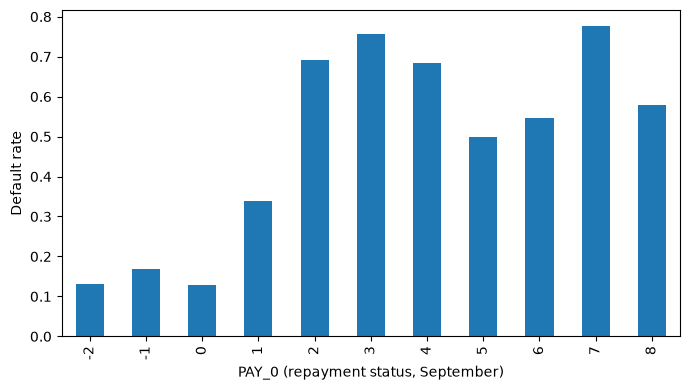

In [6]:
rate_by_pay = df.groupby("PAY_0")[TARGET].mean()
rate_by_pay.plot(kind="bar", figsize=(7, 4))
plt.xlabel("PAY_0 (repayment status, September)")
plt.ylabel("Default rate")
plt.tight_layout(); plt.show()